<a href="https://colab.research.google.com/github/RawanFarghaly/AI-Supermarket-Assistant/blob/main/ai_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/HistoricalQuotes (1).csv')

In [ ]:
df

,Date,Close/Last,Volume,Open,High,Low
0,02/28/2020,$273.36,106721200,$257.26,$278.41,$256.37
1,02/27/2020,$273.52,80151380,$281.1,$286,$272.96
2,02/26/2020,$292.65,49678430,$286.53,$297.88,$286.5
3,02/25/2020,$288.08,57668360,$300.95,$302.53,$286.13
4,02/24/2020,$298.18,55548830,$297.26,$304.18,$289.23
...,...,...,...,...,...,...
2513,03/05/2010,$31.2786,224647427,$30.7057,$31.3857,$30.6614
2514,03/04/2010,$30.1014,89591907,$29.8971,$30.1314,$29.8043
2515,03/03/2010,$29.9043,92846488,$29.8486,$29.9814,$29.7057
2516,03/02/2010,$29.8357,141486282,$29.99,$30.1186,$29.6771


In [ ]:
df.describe()

,Volume
count,2.518000e+03
mean,7.258009e+07
std,5.663113e+07
min,1.136205e+07
25%,3.053026e+07
50%,5.295469e+07
75%,9.861006e+07
max,4.624423e+08


In [ ]:
df.shape

(2518, 6)

In [ ]:
df.isna().sum()

,0
Date,0
Close/Last,0
Volume,0
Open,0
High,0
Low,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
cols = [' Close/Last', ' Open', ' High', ' Low']

for col in cols:
    df[col] = df[col].str.replace('$', '', regex=False).astype(float)

In [ ]:
df

,Date,Close/Last,Volume,Open,High,Low
0,02/28/2020,273.3600,106721200,257.2600,278.4100,256.3700
1,02/27/2020,273.5200,80151380,281.1000,286.0000,272.9600
2,02/26/2020,292.6500,49678430,286.5300,297.8800,286.5000
3,02/25/2020,288.0800,57668360,300.9500,302.5300,286.1300
4,02/24/2020,298.1800,55548830,297.2600,304.1800,289.2300
...,...,...,...,...,...,...
2513,03/05/2010,31.2786,224647427,30.7057,31.3857,30.6614
2514,03/04/2010,30.1014,89591907,29.8971,30.1314,29.8043
2515,03/03/2010,29.9043,92846488,29.8486,29.9814,29.7057
2516,03/02/2010,29.8357,141486282,29.9900,30.1186,29.6771


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2518 entries, 0 to 2517
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         2518 non-null   object 
 1    Close/Last  2518 non-null   float64
 2    Volume      2518 non-null   int64  
 3    Open        2518 non-null   float64
 4    High        2518 non-null   float64
 5    Low         2518 non-null   float64
dtypes: float64(4), int64(1), object(1)
memory usage: 118.2+ KB


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
df.columns

Index(['Date', 'Close/Last', 'Volume', 'Open', 'High', 'Low'], dtype='object')

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2518 entries, 0 to 2517
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        2518 non-null   datetime64[ns]
 1   Close/Last  2518 non-null   float64       
 2   Volume      2518 non-null   int64         
 3   Open        2518 non-null   float64       
 4   High        2518 non-null   float64       
 5   Low         2518 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 118.2 KB


In [ ]:
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

In [ ]:
df

,Date,Close/Last,Volume,Open,High,Low,year,month,day
0,2020-02-28,273.3600,106721200,257.2600,278.4100,256.3700,2020,2,28
1,2020-02-27,273.5200,80151380,281.1000,286.0000,272.9600,2020,2,27
2,2020-02-26,292.6500,49678430,286.5300,297.8800,286.5000,2020,2,26
3,2020-02-25,288.0800,57668360,300.9500,302.5300,286.1300,2020,2,25
4,2020-02-24,298.1800,55548830,297.2600,304.1800,289.2300,2020,2,24
...,...,...,...,...,...,...,...,...,...
2513,2010-03-05,31.2786,224647427,30.7057,31.3857,30.6614,2010,3,5
2514,2010-03-04,30.1014,89591907,29.8971,30.1314,29.8043,2010,3,4
2515,2010-03-03,29.9043,92846488,29.8486,29.9814,29.7057,2010,3,3
2516,2010-03-02,29.8357,141486282,29.9900,30.1186,29.6771,2010,3,2


In [ ]:
df = df.sort_values('Date')
df = df.reset_index(drop=True)

In [ ]:
df

,Date,Close/Last,Volume,Open,High,Low,year,month,day
0,2010-03-01,29.8557,137312041,29.3928,29.9286,29.3500,2010,3,1
1,2010-03-02,29.8357,141486282,29.9900,30.1186,29.6771,2010,3,2
2,2010-03-03,29.9043,92846488,29.8486,29.9814,29.7057,2010,3,3
3,2010-03-04,30.1014,89591907,29.8971,30.1314,29.8043,2010,3,4
4,2010-03-05,31.2786,224647427,30.7057,31.3857,30.6614,2010,3,5
...,...,...,...,...,...,...,...,...,...
2513,2020-02-24,298.1800,55548830,297.2600,304.1800,289.2300,2020,2,24
2514,2020-02-25,288.0800,57668360,300.9500,302.5300,286.1300,2020,2,25
2515,2020-02-26,292.6500,49678430,286.5300,297.8800,286.5000,2020,2,26
2516,2020-02-27,273.5200,80151380,281.1000,286.0000,272.9600,2020,2,27


In [ ]:
df.rename(columns={'Close/Last': 'last_Close'}, inplace=True)

In [ ]:
df.columns

Index(['Date', 'last_Close', 'Volume', 'Open', 'High', 'Low', 'year', 'month',
       'day'],
      dtype='object')

In [ ]:
print((df[['Open', 'High', 'Low', 'last_Close']] == 0).sum())
df.describe()

Open          0
High          0
Low           0
last_Close    0
dtype: int64


,Date,last_Close,Volume,Open,High,Low,year,month,day
count,2518,2518.000000,2.518000e+03,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000,2518.000000
mean,2015-02-26 15:01:17.204130304,114.769522,7.258009e+07,114.728443,115.766415,113.690582,2014.654885,6.538523,15.741461
min,2010-03-01 00:00:00,29.835700,1.136205e+07,29.392800,29.928600,28.464300,2010.000000,1.000000,1.000000
25%,2012-08-24 18:00:00,66.822475,3.053026e+07,66.877150,67.475300,66.372950,2012.000000,4.000000,8.000000
50%,2015-02-28 12:00:00,101.090000,5.295469e+07,101.115000,102.085000,100.350000,2015.000000,7.000000,16.000000
75%,2017-08-27 06:00:00,154.630000,9.861006e+07,154.610000,155.735000,153.325000,2017.000000,10.000000,23.000000
max,2020-02-28 00:00:00,327.200000,4.624423e+08,324.740000,327.850000,323.350000,2020.000000,12.000000,31.000000
std,NaN,60.662405,5.663113e+07,60.546893,61.134456,60.085105,2.898021,3.426031,8.744933


<Axes: xlabel='Volume', ylabel='Count'>

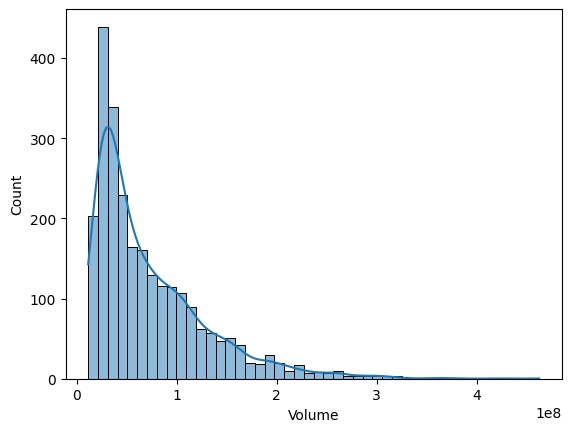

In [ ]:
sns.histplot(df['Volume'],kde = True)

<Axes: xlabel='High', ylabel='Count'>

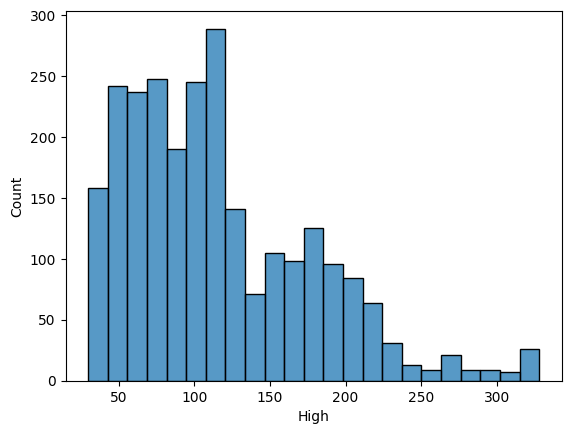

In [ ]:
sns.histplot(df['High'])

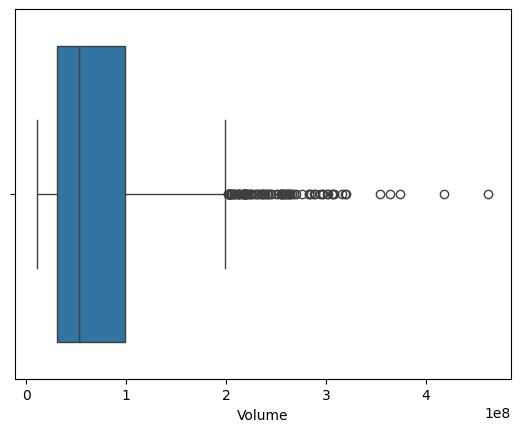

In [ ]:
sns.boxplot(x = df['Volume'])
plt.show()

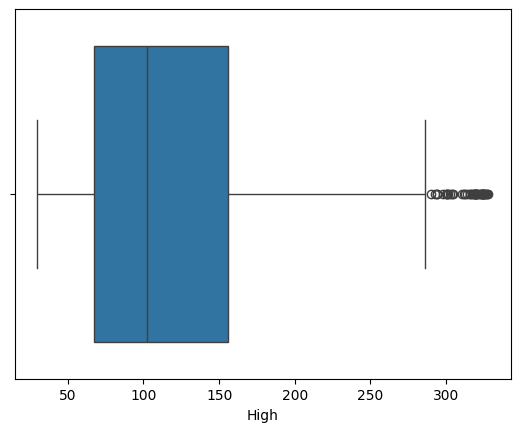

In [ ]:
sns.boxplot(x = df['High'])
plt.show()

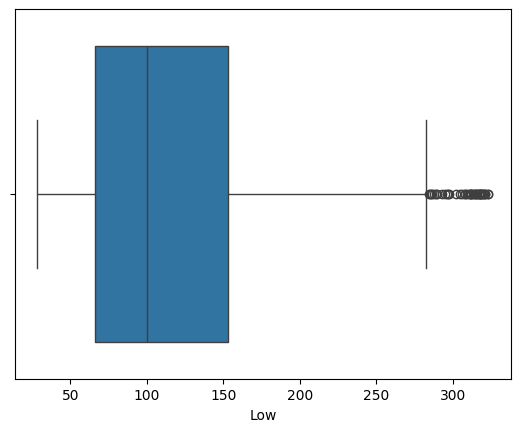

In [ ]:
sns.boxplot(x = df['Low'])
plt.show()

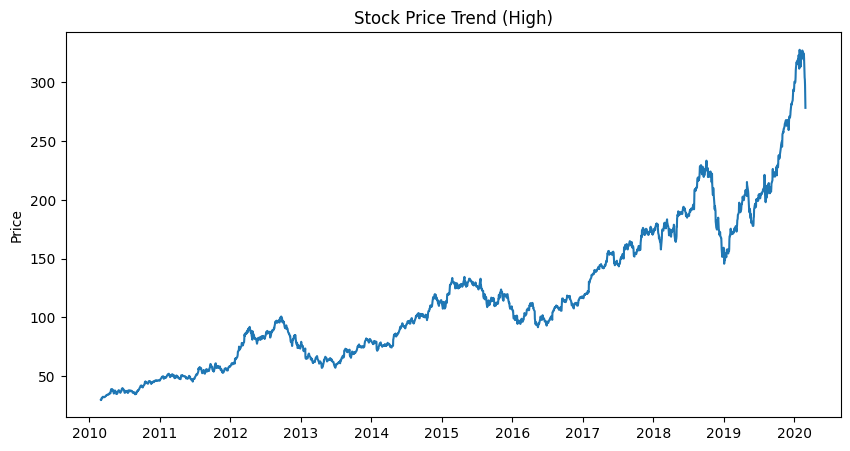

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['High'])
plt.title('Stock Price Trend (High)')
plt.ylabel('Price')
plt.show()

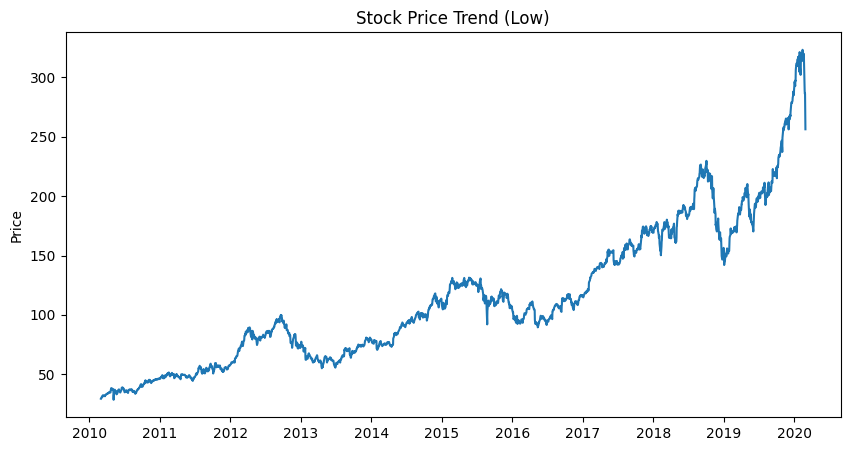

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df['Date'], df['Low'])
plt.title('Stock Price Trend (Low)')
plt.ylabel('Price')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [ ]:
X = df.drop(columns=['last_Close', 'Date'])
y = df['last_Close']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
model = LinearRegression()
model.fit(X_train_scaled , y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import mean_squared_error , mean_absolute_error,r2_score
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(mse)
print(mae)
print("R2 Score:", r2_score(y_test, y_pred))

0.46944058840827135
0.44980731686585274
R2 Score: 0.9998558562636063


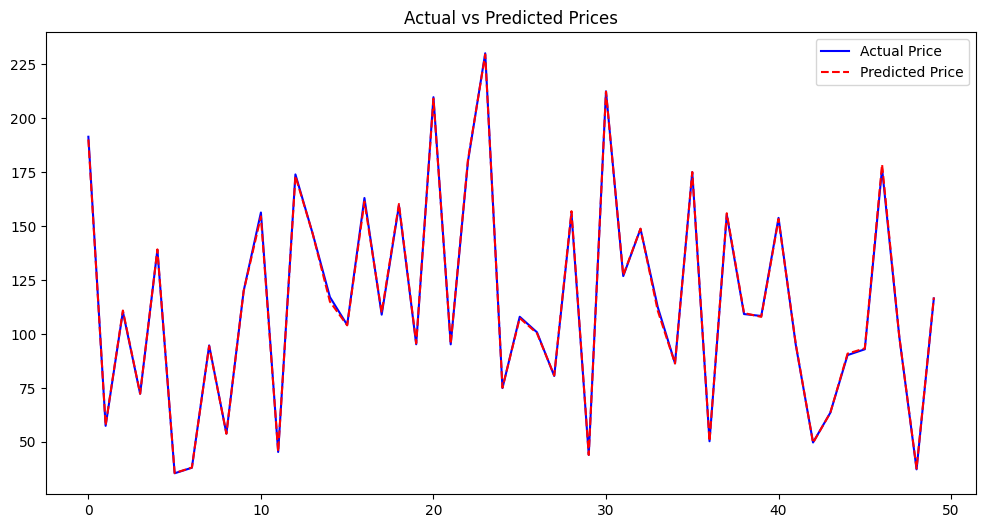

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(y_test.values[:50], label='Actual Price', color='blue')
plt.plot(y_pred[:50], label='Predicted Price', color='red', linestyle='--')
plt.title('Actual vs Predicted Prices')
plt.legend()
plt.show()

In [ ]:
df.columns

Index(['Date', 'last_Close', 'Volume', 'Open', 'High', 'Low', 'year', 'month',
       'day'],
      dtype='object')

In [ ]:
print("stock price system")

open_price = float(input("Enter the opening price: "))
high_price = float(input("Enter high price: "))
low_price = float(input("Enter low price: "))
volume = float(input("Enter volume: "))
year = float(input("Enter year: "))
month = float(input("Enter month: "))
day = float(input("Enter day: "))

user_data = pd.DataFrame({
    'Volume': [volume],
    'Open': [open_price],
    'High': [high_price],
    'Low': [low_price],
    'year': [year],
    'month' : [month],
    'day' : [day]
})
user_data_scaled = scaler.transform(user_data)

predicted_price = model.predict(user_data_scaled)

print(f"The predicted price is: {predicted_price[0]:.2f}$")

stock price system
Enter the opening price: 310.20
Enter high price: 312
Enter low price: 295.5
Enter volume: 65000000
Enter year: 2020
Enter month: 3
Enter day: 2
The predicted price is: 300.46$
